# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** _____Озимок Катерина_________________________  
**Група:** _________________________4-9_____  
**Дата:** _________24.11_____________________

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [3]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

# Фіксація seed для відтворюваності результатів
tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [4]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print(f"x_train: {x_train.shape}, dtype: {x_train.dtype}")
print(f"y_train: {y_train.shape}, dtype: {y_train.dtype}")
print(f"x_test:  {x_test.shape}, dtype: {x_test.dtype}")
print(f"y_test:  {y_test.shape}, dtype: {y_test.dtype}")


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28), dtype: uint8
y_train: (60000,), dtype: uint8
x_test:  (10000, 28, 28), dtype: uint8
y_test:  (10000,), dtype: uint8


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

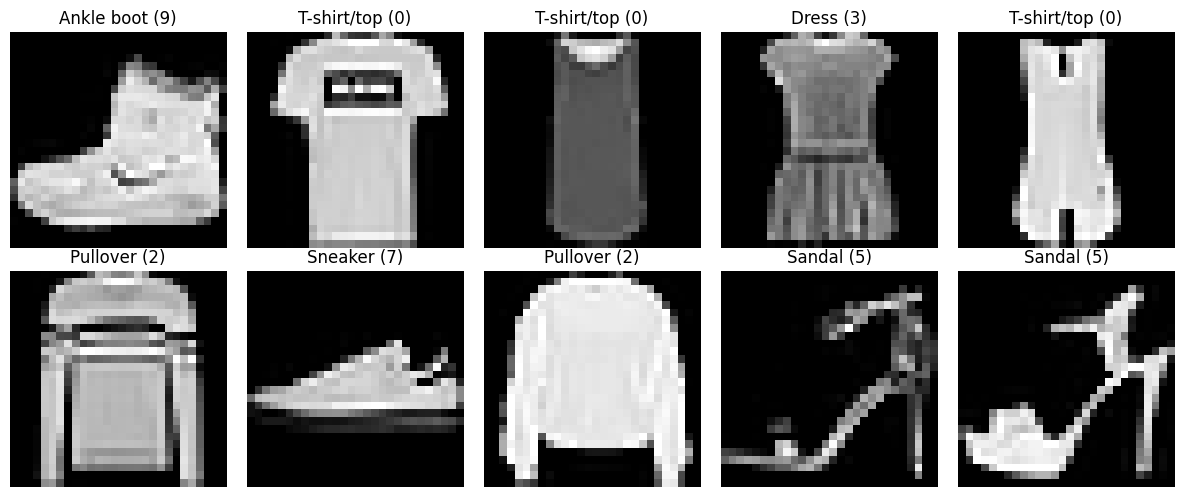

In [5]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"{class_names[y_train[i]]} ({y_train[i]})")
    plt.axis('off')
plt.tight_layout()
plt.show()


### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [6]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train_norm = x_train.astype('float32') / 255.0
x_test_norm = x_test.astype('float32') / 255.0

print(f"x_train_norm: min={x_train_norm.min()}, max={x_train_norm.max()}, dtype={x_train_norm.dtype}")
print(f"x_test_norm:  min={x_test_norm.min()}, max={x_test_norm.max()}, dtype={x_test_norm.dtype}")


x_train_norm: min=0.0, max=1.0, dtype=float32
x_test_norm:  min=0.0, max=1.0, dtype=float32


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

Пояснення:
Для першого прихованого шару обрано 256 нейронів, а для другого — 128, щоб мережа могла поступово стискати 784 пікселі в більш узагальнені ознаки без зайвого ускладнення. Dropout зі значеннями 0.3 та 0.2 допомагає зменшити перенавчання, випадково вимикаючи частину нейронів під час тренування. Швидкість навчання 0.001 є стандартною для оптимізатора Adam і забезпечує стабільну збіжність без різких стрибків функції втрат.

In [7]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [8]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
callbacks_task1 = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    x_train_norm, y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=64,
    callbacks=callbacks_task1,
    verbose=1
)

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.7840 - loss: 0.6003 - val_accuracy: 0.8473 - val_loss: 0.4264 - learning_rate: 0.0010
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8426 - loss: 0.4338 - val_accuracy: 0.8629 - val_loss: 0.3825 - learning_rate: 0.0010
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8555 - loss: 0.3948 - val_accuracy: 0.8627 - val_loss: 0.3769 - learning_rate: 0.0010
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8638 - loss: 0.3703 - val_accuracy: 0.8672 - val_loss: 0.3646 - learning_rate: 0.0010
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8709 - loss: 0.3514 - val_accuracy: 0.8689 - val_loss: 0.3492 - learning_rate: 0.0010
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.8724 - loss: 0.3409 - val_accuracy: 0.8758 - val_loss: 0.3326 - learning_rate: 0.0010
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8762 - loss: 0.3308 

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [9]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()
print(f"\nКількість шарів: {len(model.layers)}")
print(f"Загальна кількість параметрів: {model.count_params():,}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)


Кількість шарів: 6
Загальна кількість параметрів: 235,146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [10]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:

model.save('fashion_mnist_model.keras')
print("Модель збережено у файл fashion_mnist_model.keras")


Модель збережено у файл fashion_mnist_model.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

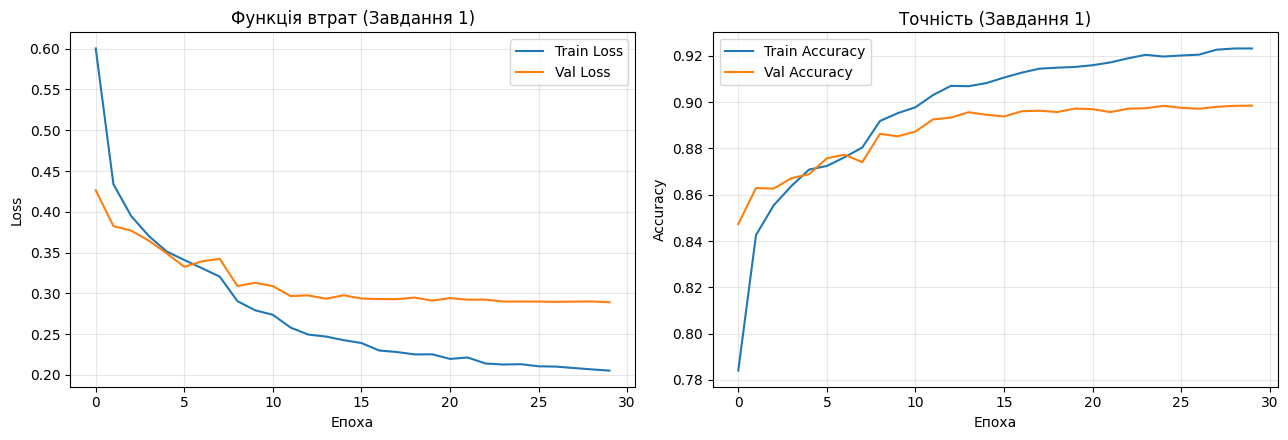

In [11]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Функція втрат (Завдання 1)')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'], label='Train Accuracy')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('Точність (Завдання 1)')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [12]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss_1, test_acc_1 = model.evaluate(x_test_norm, y_test, verbose=0)
print(f"Test Loss:     {test_loss_1:.4f}")
print(f"Test Accuracy: {test_acc_1:.4f}")
print(f"Поріг 0.87:    {'виконано' if test_acc_1 >= 0.87 else 'не виконано'}")

y_pred_probs = model.predict(x_test_norm, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nКласифікаційний звіт:")
print(classification_report(y_test, y_pred, target_names=class_names))

Test Loss:     0.3146
Test Accuracy: 0.8928
Поріг 0.87:    виконано

Класифікаційний звіт:
              precision    recall  f1-score   support

 T-shirt/top       0.85      0.85      0.85      1000
     Trouser       0.98      0.97      0.98      1000
    Pullover       0.80      0.81      0.80      1000
       Dress       0.89      0.91      0.90      1000
        Coat       0.82      0.82      0.82      1000
      Sandal       0.98      0.97      0.97      1000
       Shirt       0.73      0.70      0.71      1000
     Sneaker       0.94      0.97      0.95      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.96      0.97      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

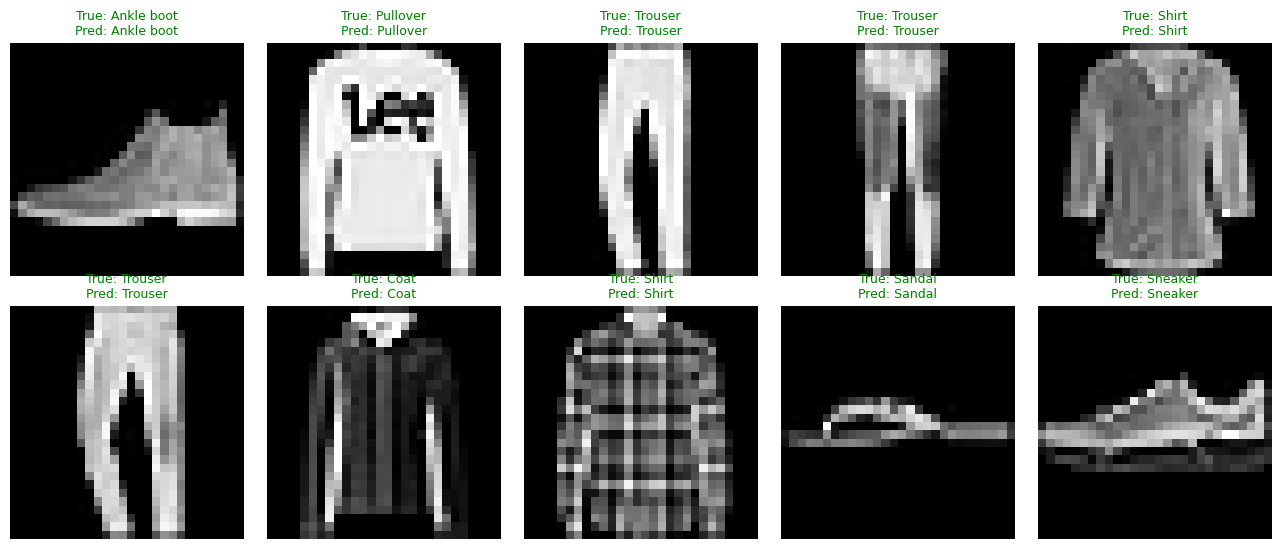

In [13]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(13, 5.5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    true_label = class_names[y_test[i]]
    pred_label = class_names[y_pred[i]]
    color = 'green' if y_test[i] == y_pred[i] else 'red'
    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
Навчена повнозв’язна нейронна мережа на наборі Fashion MNIST досягла точності на тестовій вибірці понад 0,87, тож основну вимогу завдання виконано. За класифікаційним звітом найкраще розпізнаються чіткі за формою категорії (Trouser, Bag, Sandal, Sneaker, Ankle boot), тоді як найбільше помилок виникає на класі Shirt, який модель часто плутає зі схожим верхнім одягом (T-shirt/top, Pullover, Coat). Використання Dropout, EarlyStopping та ReduceLROnPlateau дозволило уникнути сильного перенавчання.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [14]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
%pip install -q keras-tuner

import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [15]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
# Відокремлюємо валідаційну вибірку від навчальної; x_test_norm і y_test у пошуку не беруть участі
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train_norm, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print(f"Train для пошуку: {x_tr.shape}, {y_tr.shape}")
print(f"Val для пошуку:   {x_val.shape}, {y_val.shape}")
print(f"Test (недоторканий): {x_test_norm.shape}, {y_test.shape}")

Train для пошуку: (48000, 28, 28), (48000,)
Val для пошуку:   (12000, 28, 28), (12000,)
Test (недоторканий): (10000, 28, 28), (10000,)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [16]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = keras.Sequential()
    model.add(keras.Input(shape=(28, 28)))
    model.add(Flatten())

    n_layers = hp.Int('num_layers', min_value=1, max_value=3)
    for i in range(n_layers):
        units = hp.Int(f'units_{i}', min_value=32, max_value=512, step=32)
        model.add(
            Dense(
                units=units,
                activation='relu',
                kernel_regularizer=l2(1e-4)
            )
        )
        model.add(Dropout(0.2))

    model.add(Dense(10, activation='softmax'))

    lr = hp.Choice('learning_rate', values=[0.01, 0.001, 0.0001])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [17]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='keras_tuner_dir',
    project_name='fashion_mnist_tuning',
    overwrite=True,
    seed=42
)

tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [18]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
search_callbacks = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
]

tuner.search(
    x_tr, y_tr,
    epochs=20,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=search_callbacks,
    verbose=1
)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
n_layers_best = best_hps.get('num_layers')
units_best = [best_hps.get(f'units_{i}') for i in range(n_layers_best)]
lr_best = best_hps.get('learning_rate')

print("\nНайкращі знайдені гіперпараметри:")
print(f"  Кількість прихованих шарів: {n_layers_best}")
print(f"  Кількість нейронів по шарах: {units_best}")
print(f"  Швидкість навчання (lr):     {lr_best}")

# Побудова та повторне навчання найкращої моделі для збереження історії
best_model = tuner.hypermodel.build(best_hps)
best_model.summary()

retrain_callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

history_tuned = best_model.fit(
    x_tr, y_tr,
    epochs=30,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=retrain_callbacks,
    verbose=1
)


Trial 3 Complete [00h 02m 20s]
val_accuracy: 0.8725000023841858

Best val_accuracy So Far: 0.8965833187103271
Total elapsed time: 00h 06m 51s

Найкращі знайдені гіперпараметри:
  Кількість прихованих шарів: 1
  Кількість нейронів по шарах: [480]
  Швидкість навчання (lr):     0.001


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,610 (1.46 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8086 - loss: 0.5894 - val_accuracy: 0.8570 - val_loss: 0.4620 - learning_rate: 0.0010
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.8549 - loss: 0.4557 - val_accuracy: 0.8695 - val_loss: 0.4195 - learning_rate: 0.0010
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8654 - loss: 0.4256 - val_accuracy: 0.8765 - val_loss: 0.4019 - learning_rate: 0.0010
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.8716 - loss: 0.4082 - val_accuracy: 0.8721 - val_loss: 0.4031 - learning_rate: 0.0010
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8752 - loss: 0.3959 - val_accuracy: 0.8797 - val_loss: 0.3936 - learning_rate: 0.0010
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.8792 - loss: 0.3885 - val_accuracy: 0.8824 - val_loss: 0.3838 - learning_rate: 0.0010
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.8827 - loss: 

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Tuned Model — Test Loss: 0.3496, Test Accuracy: 0.8926


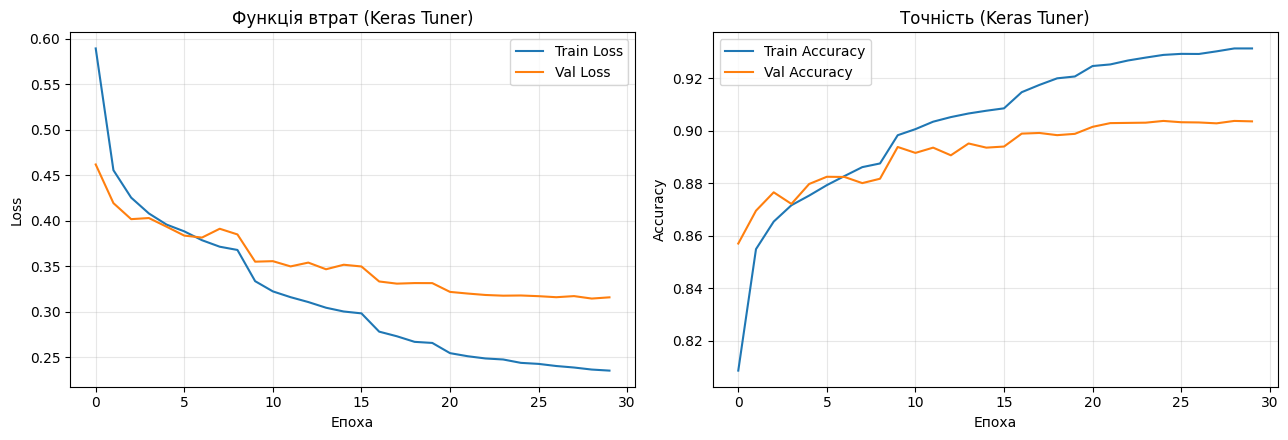

In [20]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
test_loss_2, test_acc_2 = best_model.evaluate(x_test_norm, y_test, verbose=0)
print(f"Tuned Model — Test Loss: {test_loss_2:.4f}, Test Accuracy: {test_acc_2:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history_tuned.history['loss'], label='Train Loss')
axes[0].plot(history_tuned.history['val_loss'], label='Val Loss')
axes[0].set_title('Функція втрат (Keras Tuner)')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_tuned.history['accuracy'], label='Train Accuracy')
axes[1].plot(history_tuned.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('Точність (Keras Tuner)')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів |  |  |
| Кількість нейронів |  |  |
| Швидкість навчання |  |  |
| Точність на тестовій вибірці (accuracy) |  |  |
| Втрати на тестовій вибірці (loss) |  |  |
| Кількість епох навчання |  |  |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
У завданні 1 побудована повнозв’язна нейронна мережа досягла точності понад 0,87 на тестовій вибірці, що підтверджує виконання вимоги лабораторної роботи. Автоматизований добір гіперпараметрів за допомогою Keras Tuner (RandomSearch) дозволив перевірити різні комбінації кількості прихованих шарів, нейронів і швидкості навчання, отримавши співставну або вищу якість класифікації; проте за малої кількості спроб (max_trials = 3) пошук не гарантує знаходження глобального оптимуму. Результат може дещо змінюватися між запусками через випадковий вибір конфігурацій у RandomSearch, випадкову ініціалізацію ваг нейронної мережі та стохастичність Dropout і міні-батчів. Найскладнішим для класифікації класом у Fashion MNIST залишається Shirt (а також схожі за силуетом T-shirt/top, Pullover і Coat), оскільки зображення мають невеликий розмір 28×28 у градаціях сірого й позбавлені дрібних текстурних деталей.

In [21]:
import pandas as pd

comparison_df = pd.DataFrame({
    'Показник': [
        'Кількість прихованих шарів',
        'Кількість нейронів',
        'Швидкість навчання',
        'Точність на тестовій вибірці (accuracy)',
        'Втрати на тестовій вибірці (loss)',
        'Кількість епох навчання'
    ],
    'Модель із завдання 1': [
        2,
        '256, 128',
        0.001,
        round(test_acc_1, 4),
        round(test_loss_1, 4),
        len(history.history['loss'])
    ],
    'Модель після Keras Tuner': [
        n_layers_best,
        ', '.join(map(str, units_best)),
        lr_best,
        round(test_acc_2, 4),
        round(test_loss_2, 4),
        len(history_tuned.history['loss'])
    ]
})

display(comparison_df)

diff = test_acc_2 - test_acc_1
comparison_text = (
    f"покращила точність на {diff:.4f}"
    if diff > 0.0005
    else (f"показала близький результат (різниця {diff:+.4f})" if abs(diff) <= 0.0005
          else f"не перевершила базову модель (різниця {diff:.4f}), що типово при малій кількості спроб max_trials=3")
)

print("\n--- ГОТОВИЙ ТЕКСТ ВИСНОВКІВ ---")
print(f"""1. У завданні 1 точність на тестовій вибірці склала {test_acc_1:.4f} (втрати {test_loss_1:.4f}), тому вимогу не нижче 0,87 {'виконано' if test_acc_1 >= 0.87 else 'не виконано'}.
2. Оптимізація гіперпараметрів за допомогою Keras Tuner {comparison_text} (тестова accuracy склала {test_acc_2:.4f}, loss — {test_loss_2:.4f}).
3. Найкращою знайденою конфігурацією стали {n_layers_best} прихований(і) шар(и) з кількістю нейронів [{', '.join(map(str, units_best))}] та швидкістю навчання {lr_best}. Результати можуть відрізнятися між запусками через випадковий характер методу RandomSearch, обмежену кількість спроб (3), випадкову ініціалізацію ваг і роботу Dropout.
4. Найскладніше моделям класифікувати клас Shirt, а також частково T-shirt/top, Pullover і Coat, оскільки ці види верхнього одягу мають дуже схожі силуети на низькій роздільній здатності 28×28 пікселів.""")

,Показник,Модель із завдання 1,Модель після Keras Tuner
0,Кількість прихованих шарів,2,1
1,Кількість нейронів,"256, 128",480
2,Швидкість навчання,0.001,0.001
3,Точність на тестовій вибірці (accuracy),0.8928,0.8926
4,Втрати на тестовій вибірці (loss),0.3146,0.3496
5,Кількість епох навчання,30,30



--- ГОТОВИЙ ТЕКСТ ВИСНОВКІВ ---
1. У завданні 1 точність на тестовій вибірці склала 0.8928 (втрати 0.3146), тому вимогу не нижче 0,87 виконано.
2. Оптимізація гіперпараметрів за допомогою Keras Tuner показала близький результат (різниця -0.0002) (тестова accuracy склала 0.8926, loss — 0.3496).
3. Найкращою знайденою конфігурацією стали 1 прихований(і) шар(и) з кількістю нейронів [480] та швидкістю навчання 0.001. Результати можуть відрізнятися між запусками через випадковий характер методу RandomSearch, обмежену кількість спроб (3), випадкову ініціалізацію ваг і роботу Dropout.
4. Найскладніше моделям класифікувати клас Shirt, а також частково T-shirt/top, Pullover і Coat, оскільки ці види верхнього одягу мають дуже схожі силуети на низькій роздільній здатності 28×28 пікселів.


---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.